# Análisis exploratorio de datos (EDA): segmentación de inundaciones en Perú

**Avance semana 4.** Autores: Gerson Andre Garrido Mansilla y Renzo Elvis Cerron Tome
(Maestría en Ciencias con mención en IA, UNI).

**Objetivo del EDA.** Orientado a decisiones (sílabo, semana 3–4): conocer los datos y detectar
los riesgos antes de modelar. Los riesgos revisados son:
- **fuga de información** (*leakage*);
- **desbalance de clases**;
- **cambio de dominio** (*drift*) entre Sen1Floods11 y Perú;
- **calidad de las etiquetas**.

Cada sección termina con la decisión que se tomó en el proyecto.

**Datos.**
- **Sen1Floods11:** Sentinel-2 L1C, 13 bandas, etiquetas manuales, particiones oficiales.
- **Perú 2023 (ciclón Yaku):** Lambayeque y Piura. Etiquetas automáticas a partir de los mapas
  expertos de UNOSAT.
- **Perú 2017 (Niño Costero):** Copernicus EMS EMSR199.

Recortes de 512 × 512 píxeles a 10 m. Etiqueta 1 = agua, 0 = no agua, −1 = ignorado.

**Protocolo.** Solo se leen etiquetas de entrenamiento y validación (`peru-train`, `peru-dev`,
Sen1Floods11 `train`/`valid`). De las particiones de prueba solo se muestran metadatos (ubicación,
fecha, cantidad), nunca estadísticas de etiquetas.

Ficha de datos completa: `docs/peru_data_card.md`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from IPython.display import Image, display
from matplotlib.colors import ListedColormap
%matplotlib inline
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PERU = REPO / "data/peru/unosat2023"
S1F = REPO / "data/sen1floods11/v1.1/data/flood_events/HandLabeled"
SPL = REPO / "data/sen1floods11/v1.1/splits/flood_handlabeled"
pd.set_option("display.precision", 3)
BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B10","B11","B12"]

## 1. Inventario de datos

In [2]:
m = pd.read_csv(PERU / "manifest.csv")
sp = pd.read_csv(PERU / "splits/split.csv")
m = m.merge(sp, on=["chip", "date"])
m["stem"] = m.date + "_" + m.chip
inv = m.groupby("split").agg(recortes=("chip", "size"), ubicaciones=("chip", "nunique"),
                             fechas=("date", lambda d: ", ".join(sorted(d.unique()))))
display(inv)
s1f = {k: len((SPL / f"flood_{k}_data.csv").read_text().split()) for k in ("train", "valid", "test", "bolivia")}
e17 = pd.read_csv(REPO / "data/peru/emsr2017/manifest.csv")
print("Sen1Floods11 (oficial):", s1f, "| Perú 2017 (EMSR199):", len(e17), "recortes")

,recortes,ubicaciones,fechas
split,,,
buffer,192,99,"2023-03-22, 2023-04-01"
dev,174,87,"2023-03-22, 2023-04-01"
test,172,90,"2023-03-22, 2023-04-01"
train,753,392,"2023-03-22, 2023-04-01"


Sen1Floods11 (oficial): {'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15} | Perú 2017 (EMSR199): 204 recortes


**Lectura.**
- Perú 2023 tiene dos fechas (22 de marzo y 1 de abril) de **la misma ubicación**.
- `buffer` son recortes de entrenamiento que tocan un recorte de validación o prueba. Se
  descartan.
- Bolivia no se usa (decisión de los autores).

## 2. Distribución espacial y riesgo de fuga

Si una misma ubicación aparece en entrenamiento y en prueba (por ejemplo, en otra fecha), el
modelo se evalúa sobre lugares que ya vio. Para evitarlo, la partición es **espacial**:
- se usan bloques de 4 × 4 recortes (unos 20 km), asignados al azar con semilla 0;
- las dos fechas de una ubicación van a la misma partición;
- se añade un buffer entre entrenamiento y validación/prueba.

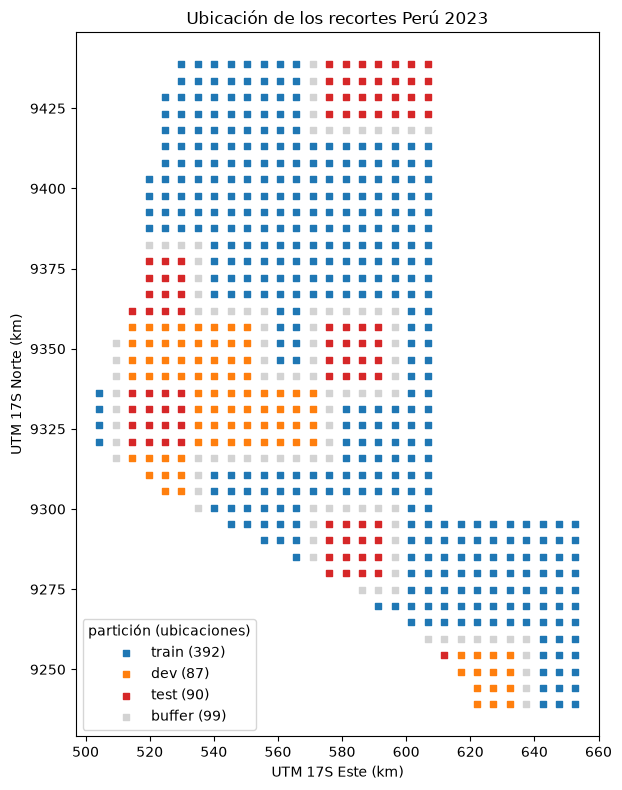

Ubicaciones con fechas en particiones distintas: 0


In [3]:
colors = {"train": "tab:blue", "dev": "tab:orange", "test": "tab:red", "buffer": "lightgray"}
loc = m.drop_duplicates("chip")
fig, ax = plt.subplots(figsize=(7, 8))
for s, c in colors.items():
    p = loc[loc.split == s]
    ax.scatter((p.minx + 2560) / 1000, (p.miny + 2560) / 1000, s=14, c=c, marker="s", label=f"{s} ({len(p)})")
ax.set_xlabel("UTM 17S Este (km)"); ax.set_ylabel("UTM 17S Norte (km)"); ax.set_aspect("equal")
ax.legend(title="partición (ubicaciones)"); ax.set_title("Ubicación de los recortes Perú 2023")
plt.tight_layout(); plt.show()
both = m.groupby("chip").split.nunique()
print("Ubicaciones con fechas en particiones distintas:", int((both > 1).sum()))

**Decisión.** Se usa la partición espacial por bloques con buffer. Ninguna ubicación aparece en
dos particiones (verificado arriba). Sen1Floods11 se usa con sus particiones oficiales, sin
volver a dividir.

## 3. Balance de clases

Fracción de agua y de píxeles ignorados por recorte (solo `peru-train`, `peru-dev` y
Sen1Floods11 `train`/`valid`).

,recortes,agua_pct_etiquetado,recortes_sin_agua_pct,ignorado_medio_pct
conjunto,,,,
peru-dev,174,12.4,36.2,13.8
peru-train,753,4.6,64.5,18.8
Sen1Floods11 train,252,9.5,13.1,13.3
Sen1Floods11 valid,89,11.0,13.5,13.0


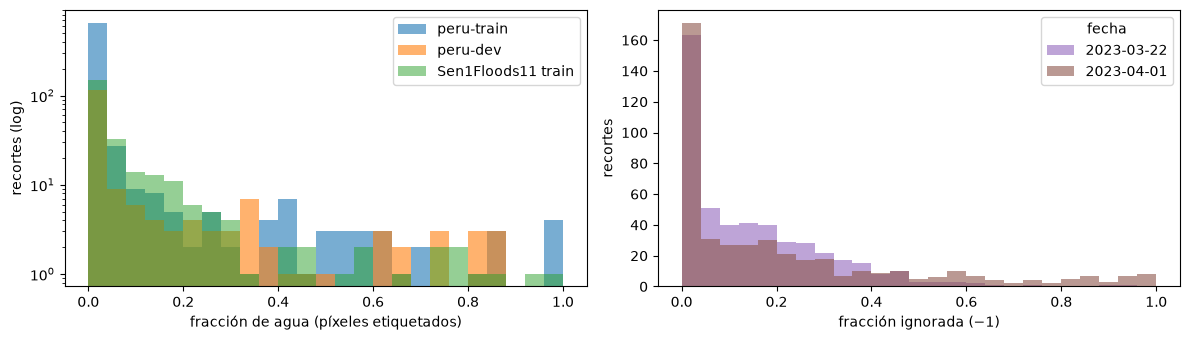

In [4]:
tv = m[m.split.isin(["train", "dev"])]
rows = []
for s, p in tv.groupby("split"):
    lab = p.water_frac + p.dry_frac
    rows.append(dict(conjunto=f"peru-{s}", recortes=len(p), agua_pct_etiquetado=100 * (p.water_frac.sum() / lab.sum()),
                     recortes_sin_agua_pct=100 * (p.water_frac == 0).mean(), ignorado_medio_pct=100 * p.ignore_frac.mean()))
s1w = {}
for k in ("train", "valid"):
    ids = [l.split(",")[0].removesuffix("_S1Hand.tif") for l in (SPL / f"flood_{k}_data.txt").read_text().split()]
    wf, n_w, n_l, ign = [], 0, 0, []
    for i in ids:
        y = rasterio.open(S1F / "LabelHand" / f"{i}_LabelHand.tif").read(1)
        lab = (y >= 0).sum(); n_w += (y == 1).sum(); n_l += lab
        wf.append((y == 1).sum() / max(lab, 1)); ign.append((y == -1).mean())
    s1w[k] = np.array(wf)
    rows.append(dict(conjunto=f"Sen1Floods11 {k}", recortes=len(ids), agua_pct_etiquetado=100 * n_w / n_l,
                     recortes_sin_agua_pct=100 * (np.array(wf) == 0).mean(), ignorado_medio_pct=100 * np.mean(ign)))
bal = pd.DataFrame(rows).set_index("conjunto"); display(bal.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.linspace(0, 1, 26)
for s, c in (("train", "tab:blue"), ("dev", "tab:orange")):
    p = tv[tv.split == s]; ax[0].hist(p.water_frac / (p.water_frac + p.dry_frac).clip(lower=1e-9), bins, alpha=0.6, color=c, label=f"peru-{s}")
ax[0].hist(s1w["train"], bins, alpha=0.5, color="tab:green", label="Sen1Floods11 train")
ax[0].set_yscale("log"); ax[0].set_xlabel("fracción de agua (píxeles etiquetados)"); ax[0].set_ylabel("recortes (log)"); ax[0].legend()
for d, c in (("2023-03-22", "tab:purple"), ("2023-04-01", "tab:brown")):
    ax[1].hist(tv[tv.date == d].ignore_frac, bins, alpha=0.6, color=c, label=d)
ax[1].set_xlabel("fracción ignorada (−1)"); ax[1].set_ylabel("recortes"); ax[1].legend(title="fecha")
plt.tight_layout(); plt.show()

**Lectura y decisión.**
- El agua es una clase **minoritaria**, sobre todo en `peru-train`, y muchos recortes no tienen
  agua.
- Por eso la exactitud (*accuracy*) no sirve como métrica: un modelo que dice "todo seco"
  acertaría casi siempre.
- **Métrica principal: IoU de la clase agua**, agrupado sobre todos los píxeles etiquetados.
  También se reportan la precisión, el recall y el mIoU de dos clases para comparar con la
  literatura.
- `peru-dev` (y `peru-test`) tienen más agua que `peru-train`, porque sus bloques se eligieron
  entre bloques con agua. Esto se tiene en cuenta al comparar entre particiones.
- Los píxeles ignorados (fuera del área analizada por UNOSAT, nubes, sin datos) se excluyen de
  la pérdida y de las métricas.

## 4. Ejemplos visuales (`peru-train`)

Tres recortes: el de más agua, uno intermedio y uno de desierto sin agua.

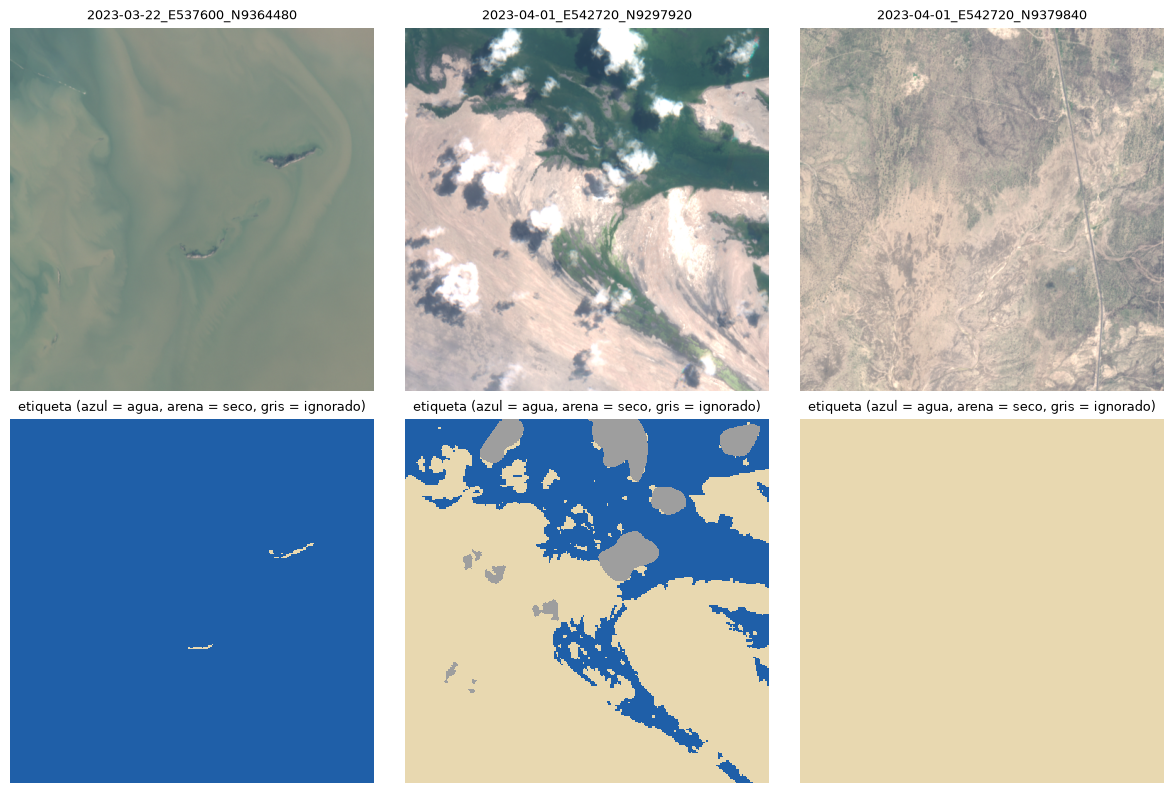

In [5]:
tr = m[m.split == "train"].copy(); tr["wf"] = tr.water_frac / (tr.water_frac + tr.dry_frac).clip(lower=1e-9)
pick = [tr.loc[tr.wf.idxmax(), "stem"], tr.loc[(tr.wf - 0.3).abs().idxmin(), "stem"],
        tr[(tr.wf == 0) & (tr.ignore_frac < 0.02)].stem.iloc[0]]
fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for j, st in enumerate(pick):
    x = rasterio.open(PERU / f"s2/{st}.tif").read().astype(np.float32)
    y = rasterio.open(PERU / f"label/{st}.tif").read(1)
    axs[0, j].imshow(np.clip(x[[3, 2, 1]].transpose(1, 2, 0) / 3000, 0, 1)); axs[0, j].set_title(st, fontsize=9)
    axs[1, j].imshow(y + 1, cmap=ListedColormap(["#9e9e9e", "#e8d8b0", "#1f5fa8"]), vmin=0, vmax=2, interpolation="nearest")
    axs[1, j].set_title("etiqueta (azul = agua, arena = seco, gris = ignorado)", fontsize=9)
for a in axs.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Distribuciones espectrales por clase y cambio de dominio

Estadísticas por banda y por clase, calculadas con `scripts/band_stats.py` sobre píxeles
etiquetados (uno de cada 37) de Sen1Floods11 `train`, `peru-train` y `peru-dev`.

El cambio se mide como **diferencia de medias estandarizada (SMD)** respecto de Sen1Floods11
`train`, en unidades de su desviación estándar. Es la escala que ve el modelo después de
normalizar.

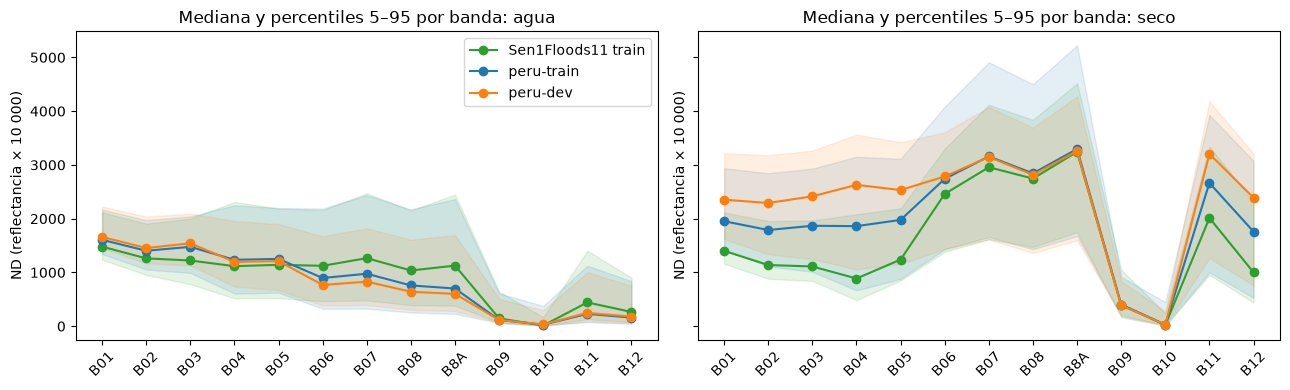

band               B01   B02   B03   B04   B05   B06   B07   B08   B8A   B09  \
dataset    cls                                                                 
peru-dev   dry    1.26  1.39  1.53  1.68  1.39  0.30  0.12  0.02 -0.03 -0.20   
           water  0.26  0.25  0.36  0.02  0.02 -0.37 -0.39 -0.36 -0.40 -0.11   
peru-train dry    0.73  0.79  0.92  0.92  0.82  0.36  0.27  0.18  0.14 -0.11   
           water  0.14  0.14  0.25  0.08  0.10 -0.19 -0.20 -0.17 -0.22 -0.06   

band               B10   B11   B12  
dataset    cls                      
peru-dev   dry    0.09  0.89  1.38  
           water  0.13 -0.18 -0.09  
peru-train dry    0.15  0.53  0.83  
           water  0.20 -0.17 -0.10

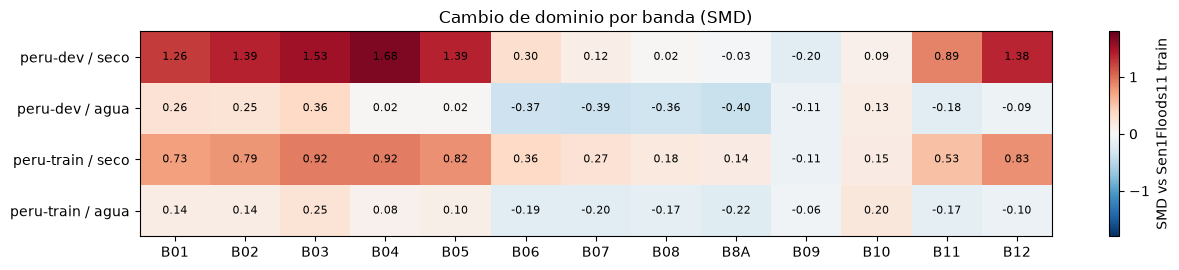

In [6]:
b = pd.read_csv(REPO / "outputs/band_stats/bands.csv")
b["band"] = b.band.str.rstrip("*")  # "*" marks Prithvi's 6 bands in the source table
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cls, t in zip(axs, ["water", "dry"], ["agua", "seco"]):
    for ds, c in (("Sen1Floods11 train", "tab:green"), ("peru-train", "tab:blue"), ("peru-dev", "tab:orange")):
        p = b[(b.dataset == ds) & (b.cls == cls)].set_index("band").reindex(BANDS)
        ax.plot(BANDS, p.p50, "o-", color=c, label=ds)
        ax.fill_between(BANDS, p.p5, p.p95, color=c, alpha=0.12)
    ax.set_title(f"Mediana y percentiles 5–95 por banda: {t}"); ax.set_ylabel("ND (reflectancia × 10 000)"); ax.tick_params(axis="x", rotation=45)
axs[0].legend(); plt.tight_layout(); plt.show()
smd = b[b.dataset != "Sen1Floods11 train"].pivot_table(index=["dataset", "cls"], columns="band", values="smd")[BANDS]
display(smd.round(2))
fig, ax = plt.subplots(figsize=(13, 2.8))
im = ax.imshow(smd.values, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
ax.set_xticks(range(len(BANDS)), BANDS); ax.set_yticks(range(len(smd)), [f"{d} / {'agua' if c=='water' else 'seco'}" for d, c in smd.index])
for i in range(smd.shape[0]):
    for j in range(smd.shape[1]): ax.text(j, i, f"{smd.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="SMD vs Sen1Floods11 train"); ax.set_title("Cambio de dominio por banda (SMD)")
plt.tight_layout(); plt.show()

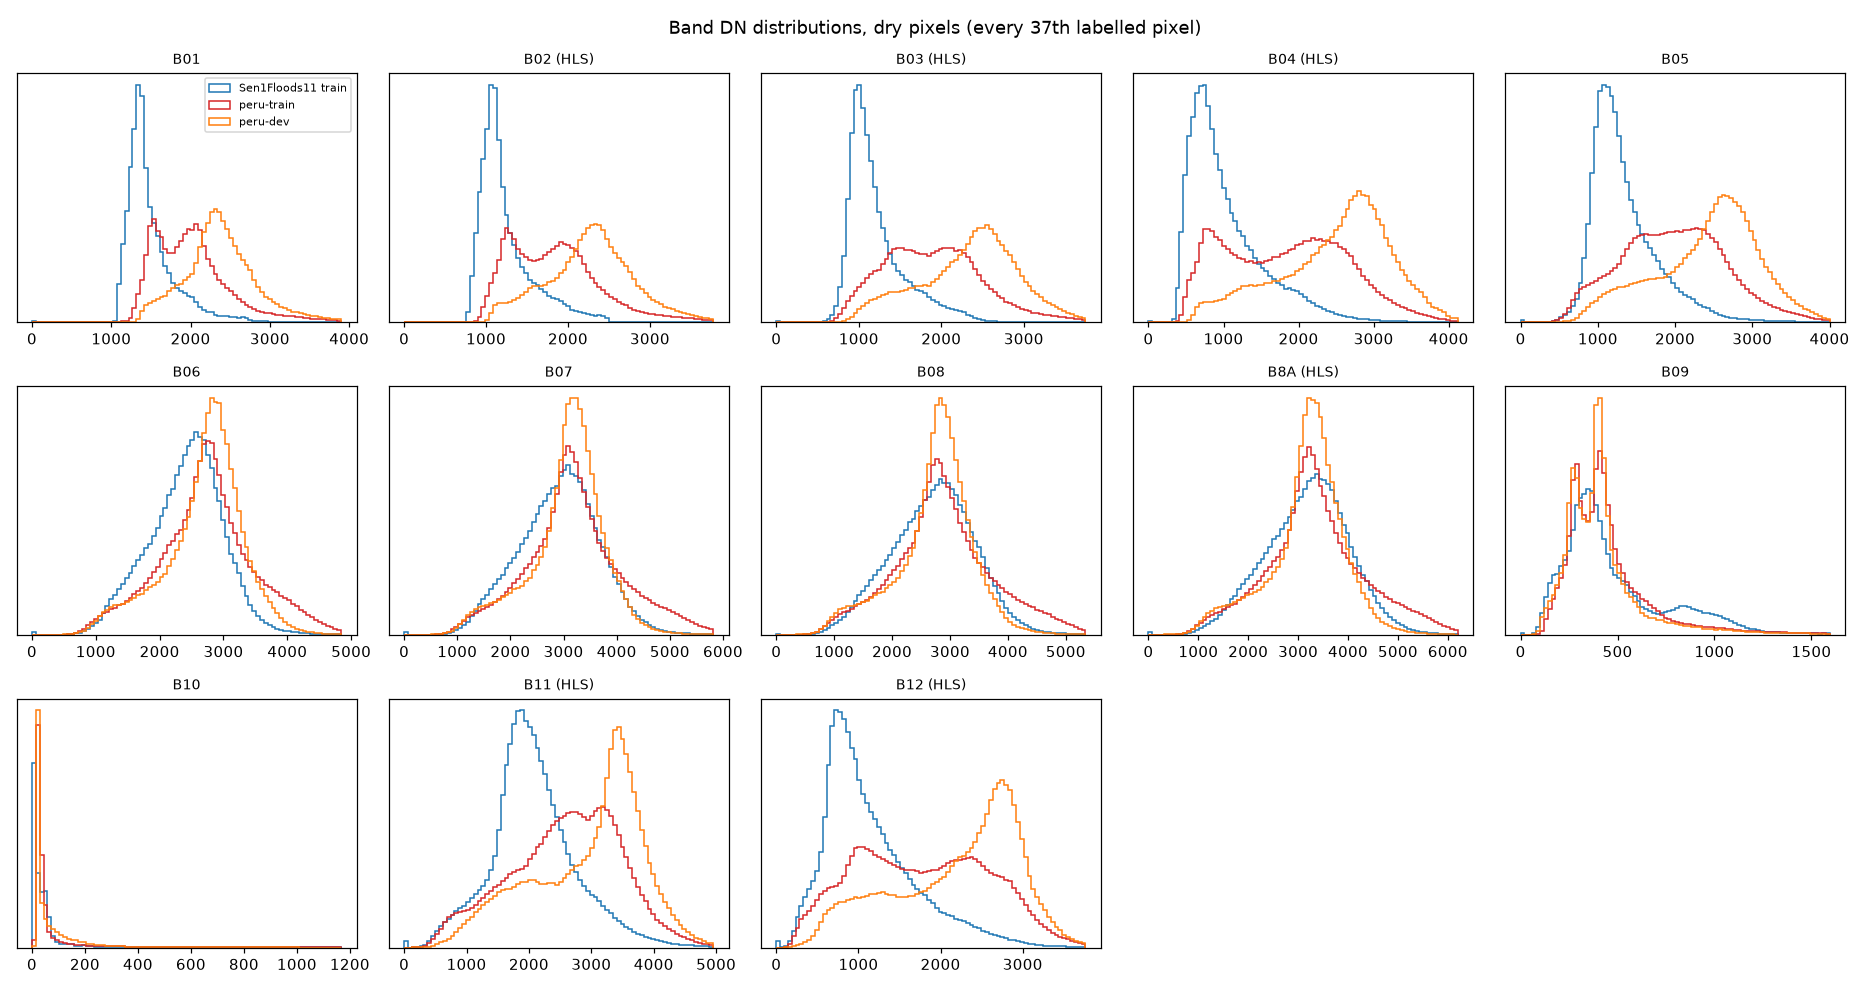

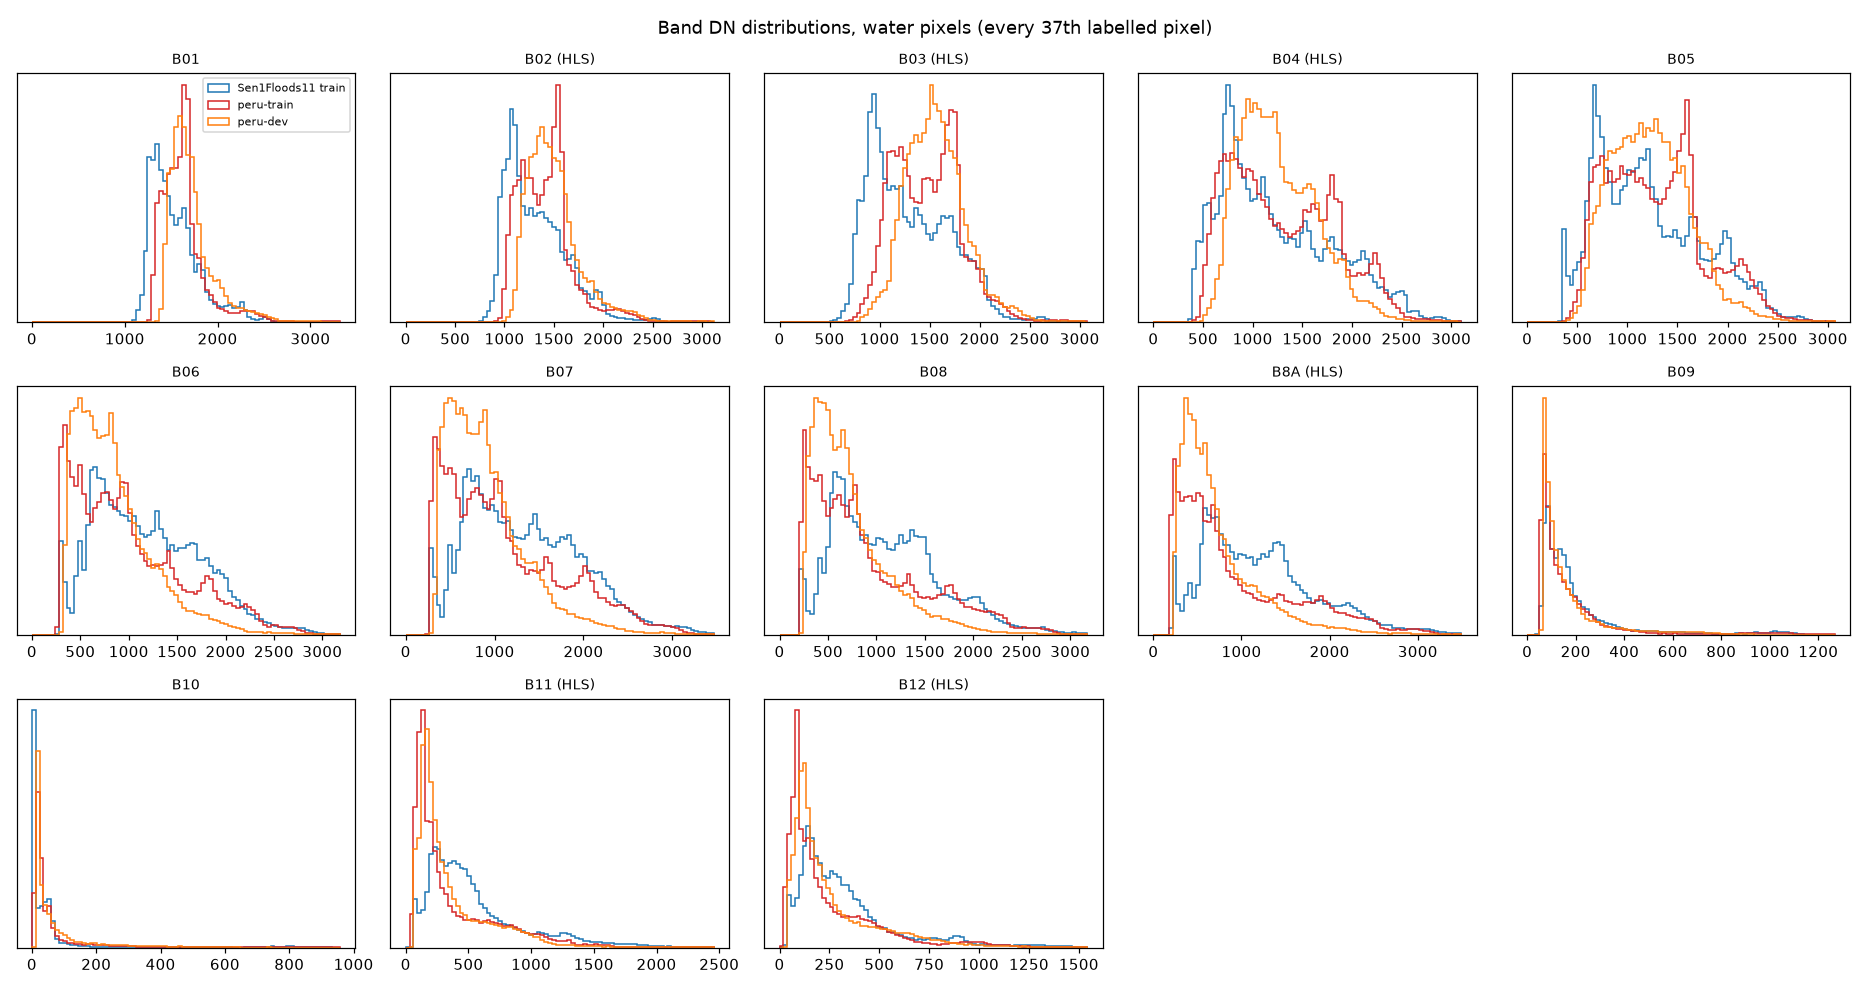

In [7]:
for f in ("hist_dry.png", "hist_water.png"):
    display(Image(filename=str(REPO / "outputs/band_stats/figs" / f), width=900))

**Lectura y decisión.**
- **El suelo seco cambia mucho más que el agua.** El desierto de Sechura es mucho más brillante en
  el visible y en el SWIR que el suelo seco de Sen1Floods11. El agua es parecida en ambos
  conjuntos.
- **Riesgo de *drift*:** un modelo entrenado en Sen1Floods11 puede confundir el desierto
  brillante con agua (falsos positivos).
- **Decisión:**
  - entrenar con datos de Perú (`peru-train`);
  - estudiar, en la fase D, la adaptación de dominio sin etiquetas peruanas (igualación de
    histogramas, FDA, AdaBN), que ataca justamente este cambio en la entrada.

## 6. Índices espectrales de agua por clase

MNDWI = (B03 − B11)/(B03 + B11) y NDWI = (B03 − B08)/(B03 + B08). Percentiles por clase.

mediana      Sen1Floods11 train  peru-dev  peru-train
index cls                                            
MNDWI dry                -0.276    -0.131      -0.172
      water               0.489     0.719       0.717
NDWI  dry                -0.376    -0.058      -0.155
      water               0.096     0.421       0.357

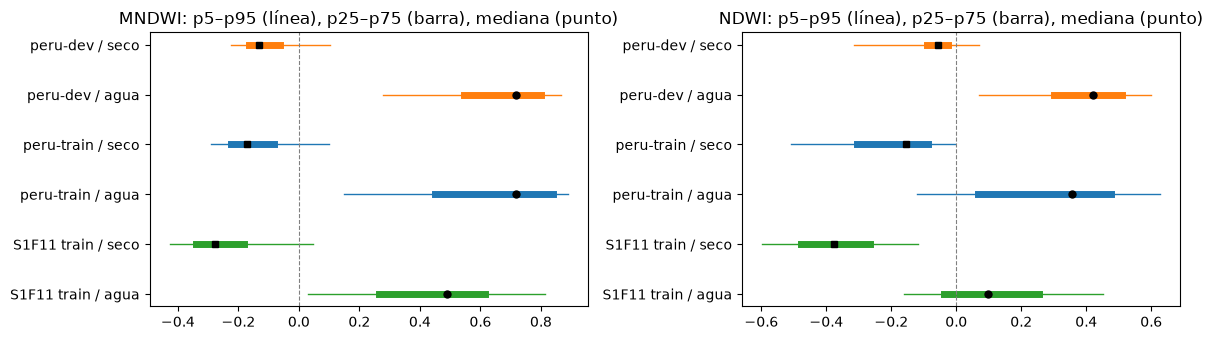

In [8]:
ix = pd.read_csv(REPO / "outputs/band_stats/indices.csv")
display(ix.pivot_table(index=["index", "cls"], columns="dataset", values="p50").round(3).rename_axis(columns="mediana"))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, idx in zip(axs, ["MNDWI", "NDWI"]):
    k = 0
    for ds, c in (("Sen1Floods11 train", "tab:green"), ("peru-train", "tab:blue"), ("peru-dev", "tab:orange")):
        for cls, mk in (("water", "o"), ("dry", "s")):
            r = ix[(ix.dataset == ds) & (ix.cls == cls) & (ix["index"] == idx)].iloc[0]
            ax.plot([r.p5, r.p95], [k, k], color=c, lw=1); ax.plot([r.p25, r.p75], [k, k], color=c, lw=5)
            ax.plot(r.p50, k, mk, color="black", ms=5); k += 1
    ax.set_yticks(range(k), [f"{d} / {'agua' if c=='water' else 'seco'}" for d in ("S1F11 train", "peru-train", "peru-dev") for c in ("water", "dry")])
    ax.axvline(0, color="gray", ls="--", lw=0.8); ax.set_title(f"{idx}: p5–p95 (línea), p25–p75 (barra), mediana (punto)")
plt.tight_layout(); plt.show()

**Lectura y decisión.**
- El agua de Perú es más clara según MNDWI que la de Sen1Floods11.
- El suelo seco de Perú tiene NDWI cercano a 0 porque es suelo desnudo. Ahí se mezcla con el
  agua de bajo contraste.
- **Decisión:**
  - incluir líneas base sin aprendizaje basadas en umbrales de MNDWI;
  - usar MNDWI para el control de calidad de las etiquetas (sección 8) y para analizar los
    errores por estrato.

## 7. Correlación entre bandas (`peru-train`)

Muestra de píxeles válidos: 1 de cada 50, en 60 recortes de entrenamiento elegidos al azar con
semilla 0.

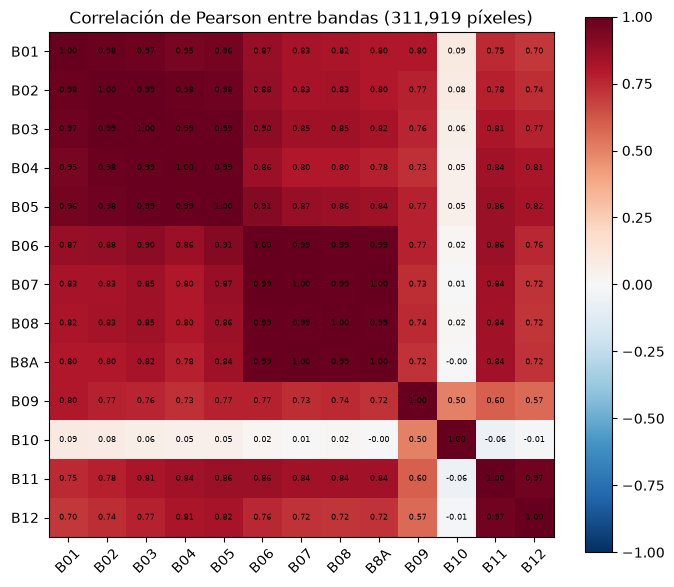

In [9]:
rng = np.random.default_rng(0)
stems = rng.choice(m[m.split == "train"].stem.values, 60, replace=False)
X = []
for st in stems:
    x = rasterio.open(PERU / f"s2/{st}.tif").read().reshape(13, -1).astype(np.float32)
    x = x[:, (x != 0).any(0)][:, ::50]; X.append(x)
X = np.concatenate(X, 1)
C = np.corrcoef(X)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(13), BANDS, rotation=45); ax.set_yticks(range(13), BANDS)
for i in range(13):
    for j in range(13): ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax); ax.set_title(f"Correlación de Pearson entre bandas ({X.shape[1]:,} píxeles)")
plt.tight_layout(); plt.show()

**Lectura.**
- Las bandas visibles (B02–B04) están muy correlacionadas entre sí.
- Lo mismo ocurre con el borde rojo y el NIR (B06–B8A) y con los dos SWIR (B11, B12).
- La información es redundante dentro de cada grupo. El contraste útil para el agua está *entre*
  grupos (visible frente a SWIR/NIR), que es lo que miden los índices.

**Decisión.**
- No se eliminan bandas para U-Net y TerraMind (13 bandas), porque cada modelo usa su
  configuración oficial.
- Prithvi usa sus 6 bandas de preentrenamiento.
- El estudio de características diseñadas está en el avance de la semana 5
  (`notebooks/feature_engineering.ipynb`).

## 8. Calidad de las etiquetas

Las etiquetas vienen de mapas expertos convertidos automáticamente, sin revisión manual. Para
revisarlas, se marcan las manchas de al menos 1 ha que contradicen claramente el índice
(`scripts/label_qa.py`):
- **omisión:** etiquetado seco con MNDWI > 0.5;
- **comisión:** etiquetado agua con MNDWI < −0.1.

Un recorte es "dudoso" según el área de esas manchas.

In [10]:
qa = pd.read_csv(REPO / "outputs/label_qa/chips.csv")
qa = qa[qa.split.isin(["train", "dev"])]
display(pd.crosstab(qa.split, qa.flag, margins=True))
print("Área marcada (ha) por tipo, train+dev:")
display(qa[["omission_open_ha", "omission_vegetated_ha", "omission_near_cloud_ha",
            "commission_open_ha", "commission_vegetated_ha", "commission_near_cloud_ha"]].sum().round(0).to_frame("ha"))

flag,doubtful,minor,ok,All
split,,,,
dev,8,6,160,174
train,16,40,697,753
All,24,46,857,927


Área marcada (ha) por tipo, train+dev:


,ha
omission_open_ha,187.0
omission_vegetated_ha,0.0
omission_near_cloud_ha,122.0
commission_open_ha,14.0
commission_vegetated_ha,1.0
commission_near_cloud_ha,0.0


**Lectura y decisión.**
- Pocos recortes son dudosos. Las etiquetas v1 se congelan sin corregirlas a mano.
- En la evaluación se reporta además un subconjunto **sin recortes dudosos** como análisis de
  sensibilidad, definido antes de mirar los resultados de prueba.

## 9. Conclusiones accionables

| Riesgo | Hallazgo | Decisión |
|---|---|---|
| Fuga de información | La misma ubicación aparece en dos fechas | Partición espacial por bloques con buffer; ninguna ubicación en dos particiones |
| Desbalance | El agua es minoritaria; muchos recortes sin agua | IoU de agua agrupado (no exactitud); se reportan precisión y recall; el área ignorada se excluye |
| Diferencia entre particiones | `peru-dev`/`peru-test` con más agua que `peru-train` | Se compara siempre dentro de la misma partición; las conclusiones usan diferencias pareadas |
| Cambio de dominio | El suelo seco peruano es mucho más brillante que el de Sen1Floods11; el agua es parecida | Entrenar con `peru-train`; adaptación de dominio sin etiquetas en la fase D |
| Separabilidad | MNDWI separa bien el agua de Perú | Líneas base por umbral de MNDWI; índices para el control de calidad y el análisis de errores |
| Ruido en etiquetas | Pocos recortes contradicen claramente a MNDWI | Etiquetas congeladas; subconjunto sin recortes dudosos como sensibilidad |
| Nubes | Los detectores estándar (s2cloudless, SCL) marcan el desierto como nube | Regla propia de nube espesa; las nubes se ignoran (−1) |

Detalle completo: `docs/peru_data_card.md`, `docs/domain_shift_dev.md`,
`docs/peru_doubtful_chips.md`.